In [14]:
import numpy as np 
import pandas as pd

In [15]:
df = pd.read_csv("Powerplant dataset.csv")
df

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43
...,...,...,...,...,...
9563,15.12,48.92,1011.80,72.93,462.59
9564,33.41,77.95,1010.30,59.72,432.90
9565,15.99,43.34,1014.20,78.66,465.96
9566,17.65,59.87,1018.58,94.65,450.93


In [16]:
df.shape    

(9568, 5)

In [17]:
# splitting the data

X = df.drop("PE", axis=1)
y = df["PE"]


In [18]:
y.head()

0    480.48
1    445.75
2    438.76
3    453.09
4    464.43
Name: PE, dtype: float64

In [19]:
# train test split
from sklearn.model_selection import train_test_split

X_train, X_test , y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42,
)

In [20]:
y_test.head()

2513    433.27
9411    438.16
8745    458.42
9085    480.82
4950    441.41
Name: PE, dtype: float64

In [21]:
# Scaling data
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [22]:
# Converting into tensors

import torch
import torch.nn as nn

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)  # view converts df to tensors '-1' automatically detects appropriate rows

X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1)

In [23]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32)


In [28]:
# Defining the model

class ANN(nn.Module):
    def __init__(self):
        super(ANN, self).__init__()

        self.model = nn.Sequential(
            # 1st hidden layer
            nn.Linear(X_train.shape[1], 6),  # (in_features, out_features)
            nn.ReLU(),

            # 2nd hidden layer
            nn.Linear(6, 6),
            nn.ReLU(),

            # Output layer
            nn.Linear(6, 1)
        )

    def forward(self, x):
        return self.model(x)


In [29]:
import torch.optim as optim

model = ANN()

# loss, optimiser
criterion = nn.MSELoss()
optimiser = optim.Adam(model.parameters())

In [30]:
# Training the ANN

train_losses = []
val_losses = []
best_val_loss = float("inf")
epochs = 100  # epochs contain multiple batches

for epoch in range(epochs):  # we will train the model in each individual epoch
    model.train()  # train the model
    running_train_loss = 0.0  # Total loss of 1 epoch

    for xb, yb in train_loader:  # train_loader gives us the batches
        optimiser.zero_grad()  # reset gradients before backpropagation
        outputs = model(xb)  # predicted output - forward prop
        loss = criterion(outputs, yb)  # calc loss
        loss.backward()  # back prop... compute gradients to adjust our weights
        optimiser.step()  # update params
        running_train_loss += loss.item()  # converts tensor to float

    epoch_train_loss = running_train_loss / len(train_loader)
    train_losses.append(epoch_train_loss)

    # Validation
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():  # no params computed
        for xb, yb in test_loader:
            outputs = model(xb)  # predicted output - forward prop
            loss = criterion(outputs, yb)  # calc loss
            running_val_loss += loss.item()

    epoch_val_loss = running_val_loss / len(test_loader)
    val_losses.append(epoch_val_loss)

    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(), "best_model.pt") # extensions-> .pt or .pth

    print(f"epoch = {epoch + 1}/{epochs} => train loss = {epoch_train_loss} & validation loss = {epoch_val_loss}")


epoch = 1/100 => train loss = 205591.941015625 & validation loss = 202334.55598958334
epoch = 2/100 => train loss = 191810.16276041666 & validation loss = 175659.41119791666
epoch = 3/100 => train loss = 148128.10224609374 & validation loss = 116450.76119791667
epoch = 4/100 => train loss = 86696.66031901042 & validation loss = 61689.54485677083
epoch = 5/100 => train loss = 45115.67647298177 & validation loss = 32026.74970703125
epoch = 6/100 => train loss = 22743.054939778645 & validation loss = 15858.839306640624
epoch = 7/100 => train loss = 11732.194908650716 & validation loss = 9126.738793945313
epoch = 8/100 => train loss = 7371.332145182291 & validation loss = 6281.555741373698
epoch = 9/100 => train loss = 5277.343951416015 & validation loss = 4624.226615397135
epoch = 10/100 => train loss = 3939.217669169108 & validation loss = 3468.7304219563803
epoch = 11/100 => train loss = 2947.5108812967937 & validation loss = 2599.6176940917967
epoch = 12/100 => train loss = 2201.409125

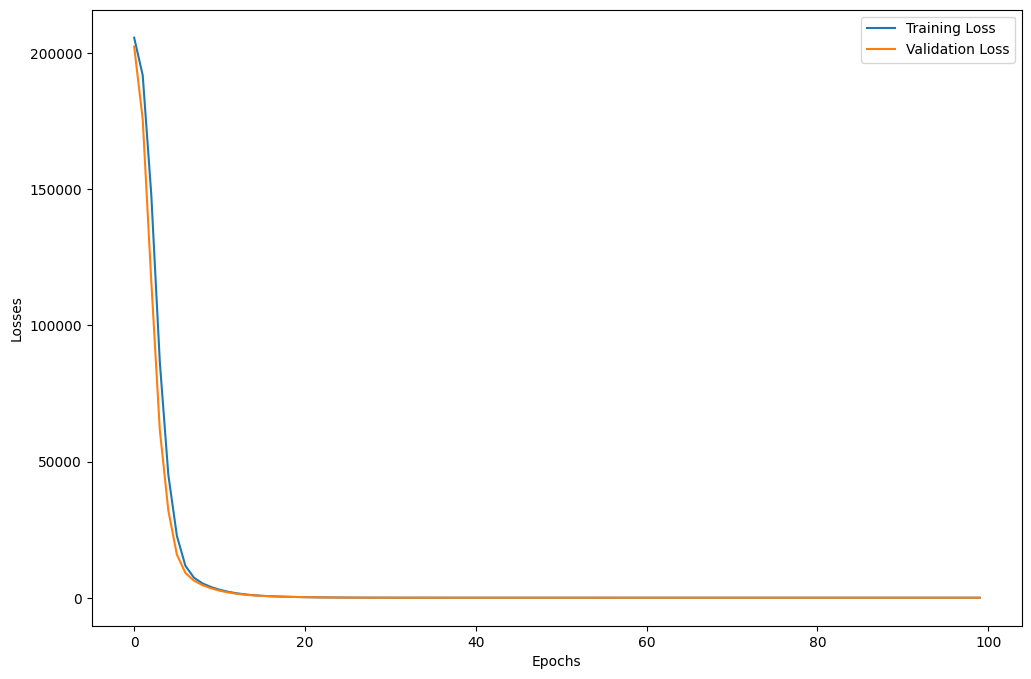

In [31]:
import matplotlib.pyplot as plt

loss_df = pd.DataFrame({
    "Training Loss": train_losses,
    "Validation Loss": val_losses
})

plt.figure(figsize=(12, 8))

plt.plot(loss_df["Training Loss"], label="Training Loss")
plt.plot(loss_df["Validation Loss"], label="Validation Loss")
plt.legend()

plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.show()


In [32]:
# Loading the best model (torch.load())

model.load_state_dict(torch.load("best_model.pt"))

<All keys matched successfully>

In [34]:
# Evaluating our model
model.eval()
with torch.no_grad():
    train_preds = model(X_train_tensor)
    test_preds = model(X_test_tensor)

    train_mse_loss = criterion(train_preds, y_train_tensor)
    test_mse_loss = criterion(test_preds, y_test_tensor)

print("MSE for trainig data:", train_mse_loss.item())
print("MSE for testing data", test_mse_loss.item())

MSE for trainig data: 21.08905792236328
MSE for testing data 19.66153907775879


In [35]:
# r2_score

from sklearn.metrics import r2_score

print("r2 score:", r2_score(y_test, test_preds))

r2 score: 0.9312879954868531


In [ ]:
# COnverting values into dataframe
predicted_df = pd.DataFrame(test_preds.numpy(), columns=["Predicted Values"])
actual_df = pd.DataFrame(y_test.values, columns=["Actual Values"])

# join the values
pd.concat([predicted_df, actual_df], axis=1)

,Predicted Values,Actual Values
0,435.658264,433.27
1,437.370636,438.16
2,461.599823,458.42
3,476.452271,480.82
4,435.979584,441.41
...,...,...
1909,451.485901,456.70
1910,432.063873,438.04
1911,467.818085,467.80
1912,431.566071,437.14
